# Eigensystem Solutions

This notebook is an example of solving the ABS system for the theta wake with wake parameter $w = 1$.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
    
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.colors as mcolors
import inspect

In [2]:
from pyabs.core.basis import ABSBasisConfig, build_abs_basis
from pyabs.core.matrix import build_abs_matrix, build_abs_matrix_parts
from pyabs.core.wake import ThetaWake, WakeScale
from pyabs.solvers.eigensolvers import solve_eigensystem#, solve_system
from pyabs.solvers.systemsolvers import solve_system

In [3]:
n_max=500
basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=20))

In [4]:
theta_wake = ThetaWake(W0=1)

In [5]:
matrix = build_abs_matrix(basis, wake_model=theta_wake, scale=WakeScale(w = 1.0))

In [6]:
#eigenvalue_i, eigenvectors_i 
eigensolution = solve_eigensystem(matrix)
eigenvalues = np.array(eigensolution.eigenvalues)
eigenvectors= np.array(eigensolution.eigenvectors)

# Solutions

### solve_system

In [7]:
solution = solve_system(matrix, A0=1)

## Testing

### solution.compute_x, solution.compute_xplus, solution.compute_xminus

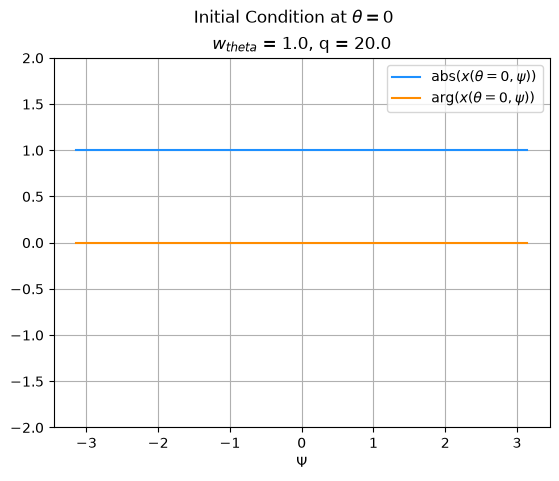

In [8]:
psi_range = np.linspace(-np.pi, np.pi, 100)
yabs = []
yarg = []
for psi in psi_range:
    soln = solution.compute_x(theta=0, psi=psi)
    yabs.append(np.abs(soln))
    yarg.append(np.angle(soln))

fig, ax = plt.subplots()
ax.set_ylim(-2,2)
plt.suptitle(r"Initial Condition at $\theta = 0$")
plt.title(r"$w_{theta}$ = 1.0, q = 20.0")
plt.grid()
plt.plot(psi_range, yabs, color='dodgerblue', label = r"abs($x$($\theta=0, \psi$))")
plt.plot(psi_range, yarg, color='darkorange', label = r"arg($x$($\theta=0, \psi$))")
#ax.set_ylabel(r"$\nu_{k}$")
plt.legend()
ax.set_xlabel(r"$\Psi$")
plt.savefig("../../plots/initial_condition_confirmation.png", dpi=300)
plt.show()

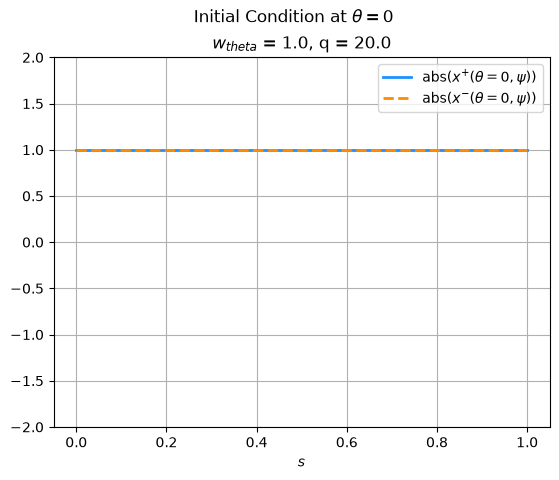

In [9]:
s_range = np.linspace(0, 1, 100)
plusabs = []
minusabs = []
for s in s_range:
    plus = solution.compute_xplus(theta=0, s=s)
    minus= solution.compute_xminus(theta=0, s=s)
    plusabs.append(np.abs(plus))
    minusabs.append(np.abs(minus))

fig, ax = plt.subplots()
ax.set_ylim(-2,2)
plt.suptitle(r"Initial Condition at $\theta = 0$")
plt.title(r"$w_{theta}$ = 1.0, q = 20.0")
plt.grid()
plt.plot(s_range, plusabs, color='dodgerblue',lw=2.0, label = r"abs($x^{\plus}$($\theta=0, \psi$))")
plt.plot(s_range, minusabs, color='darkorange',lw=2.0, ls = "--", label = r"abs($x^{\minus}$($\theta=0, \psi$))")
#ax.set_ylabel(r"$\nu_{k}$")
plt.legend()
ax.set_xlabel(r"$s$")
plt.savefig("../../plots/initialcond_sversion.png", dpi=300)
plt.show()

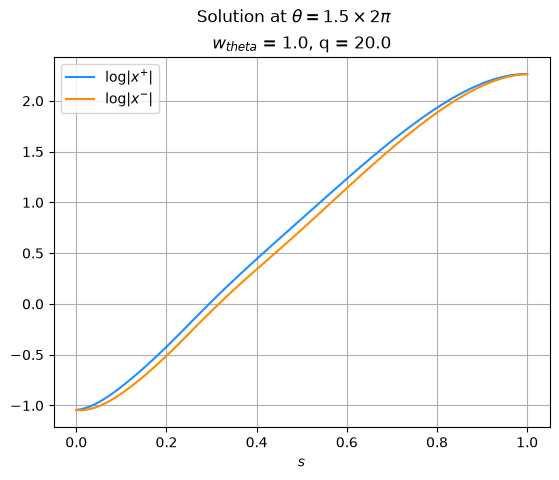

In [10]:
s_range = np.linspace(0, 1, 100)
logplusabs = []
logminusabs = []
for s in s_range:
    plus = solution.compute_xplus(theta=1.5*2*np.pi, s=s)
    minus= solution.compute_xminus(theta=1.5*2*np.pi, s=s)
    logplusabs.append(np.log(np.abs(plus)))
    logminusabs.append(np.log(np.abs(minus)))
    
fig, ax = plt.subplots()
#ax.set_ylim(-2,2)
plt.suptitle(r"Solution at $\theta = 1.5\times2\pi$")
plt.title(r"$w_{theta}$ = 1.0, q = 20.0")
plt.grid()
plt.plot(s_range, logplusabs, color='dodgerblue', label = r"log|$x^{\plus}$|")
plt.plot(s_range, logminusabs, color='darkorange',label = r"log|$x^{\minus}$|")
#ax.set_ylabel(r"$\nu_{k}$")
plt.legend()
ax.set_xlabel(r"$s$")
plt.savefig("../../plots/latersolution.png", dpi=300)
plt.show()

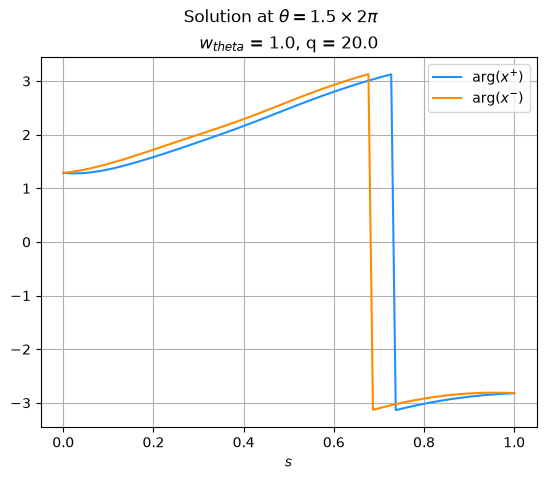

In [11]:
s_range = np.linspace(0, 1, 100)
logplusabs = []
logminusabs = []
for s in s_range:
    plus = solution.compute_xplus(theta=1.5*2*np.pi, s=s)
    minus= solution.compute_xminus(theta=1.5*2*np.pi, s=s)
    logplusabs.append(np.angle(plus))
    logminusabs.append(np.angle(minus))
    
fig, ax = plt.subplots()
#ax.set_ylim(-2,2)
plt.suptitle(r"Solution at $\theta = 1.5\times2\pi$")
plt.title(r"$w_{theta}$ = 1.0, q = 20.0")
plt.grid()
plt.plot(s_range, logplusabs, color='dodgerblue', label = r"arg($x^{\plus}$)")
plt.plot(s_range, logminusabs, color='darkorange', label = r"arg($x^{\minus}$)")
#ax.set_ylabel(r"$\nu_{k}$")
plt.legend()
ax.set_xlabel(r"$s$")
plt.savefig("../../plots/latersolution_arg.png", dpi=300)
plt.show()

In [12]:
ks, modes = solution.compute_amplification_factors()
kmax = np.max(ks)

In [13]:
k_0 = solution.compute_amplification_factors(mode=0)
k_0

np.float64(27.096562851831862)

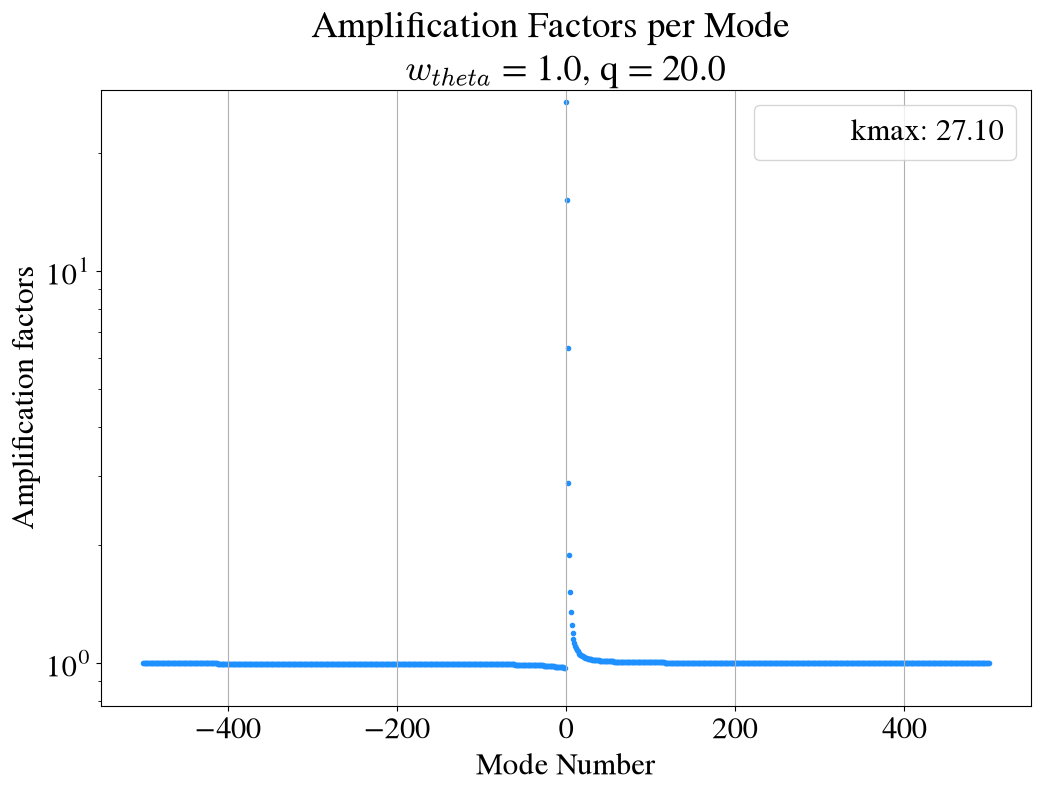

In [34]:
import matplotlib as mpl
mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 22
fig, ax = plt.subplots()
fig.set_figheight(8)
fig.set_figwidth(12)
plt.suptitle(r"Amplification Factors per Mode")
plt.title(r"$w_{theta}$ = 1.0, q = 20.0")
plt.scatter(modes, ks, marker='.', color='dodgerblue')
plt.scatter([],[], marker='none',label = f"kmax: {kmax:.2f}")
ax.set_xlabel(r"Mode Number")
ax.set_ylim(0.8*np.min(ks), kmax+2)
plt.ylabel("Amplification factors")
plt.yscale('log')
plt.legend(loc='upper right')
plt.grid(axis='x')
#plt.tight_layout()
plt.savefig("../../plots/amplification_factors_theta", dpi=300)
plt.show()

In [35]:
from tqdm.notebook import tqdm
strobo_modes = np.arange(-3,3, dtype = int)
psirange=np.linspace(0, np.pi, 600)
test = []
with tqdm(total=len(psirange), desc="Solving centroid strobes") as pbar:
    for psi in psirange:
        test.append(solution.compute_centroidstrobe(psi=psi, ns = 20, modes=strobo_modes))
        pbar.update(1)
    pbar.set_postfix(psi=f"{psi:.2f}")
test = np.array(test)
test.shape

Solving centroid strobes:   0%|          | 0/600 [00:00<?, ?it/s]

(600, 6, 20)

In [36]:
int(np.ceil((len(strobo_modes)-1)/2))

3

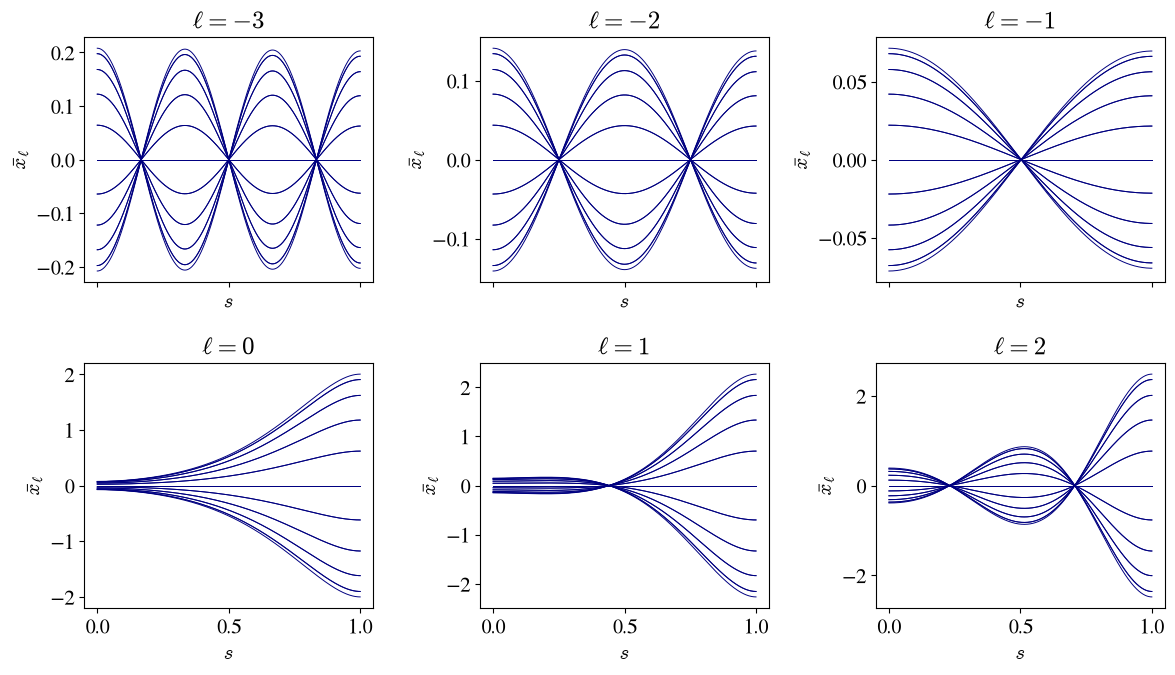

In [44]:
#modes = [5]
sub_max = int(np.ceil((len(strobo_modes)-1)/2))
strobo_modes = np.arange(-3,3, dtype = int)
plot_modes = strobo_modes + n_max
n_size = len(strobo_modes)
ncols = 3
nrows = int(np.ceil(n_size / ncols))
fig.set_figheight(8)
fig.set_figwidth(12)
mpl.rcParams['font.size'] = 15
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), sharex=True, sharey=False)

axes = np.array(axes).reshape(-1)  # flatten in case nrows/ncols > 1
for ax, mode in zip(axes, strobo_modes):
    for k in range(test.shape[2]):
        ydat = test[:, mode+sub_max, k]
        ax.plot(psirange/np.pi, ydat, color = 'navy', lw=0.7)
        #ax.set_ylim(np.min(ydat), np.max(ydat))
    ax.set_title(fr'$\ell = {mode}$')
    #ax.set_ylim(np.min(test[:,mode+n_max,k]), np.max(test[:,mode+n_max,k]))
    ax.set_ylabel(r'$\bar{x}_\ell$')
    ax.set_xlabel(r'$s$')

for ax in axes[n_size:]:
    ax.set_visible(False)

fig.savefig("../../plots/stroboscopic_theta.png", dpi=900)
fig.tight_layout()
plt.show()

In [239]:
%%time
from tqdm.notebook import tqdm
resolution = 100
n_max = 20
n_modes = 2*n_max + 1
qmax = 50
wmax = 100
qrange = np.linspace(0.0, qmax, num=resolution)
wrange = np.linspace(0.0, wmax, num=resolution)
log_kmax = np.empty((resolution, resolution), dtype=float)

with tqdm(total=resolution * resolution, desc="Solving eigenvalues") as pbar:
    for i, q in enumerate(qrange):
        basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=q))
        for j, w in enumerate(wrange):
            theta_wake = ThetaWake(W0=1)
            matrix = build_abs_matrix(basis, wake_model=theta_wake, scale=WakeScale(w=w))
            solution = solve_system(matrix, A0=1)
            log_kmax[j][i] = np.log10(np.max(solution.compute_amplification_factors()))
            pbar.update(1)
        pbar.set_postfix(q=f"{q:.1f}")

rows, cols = np.meshgrid(np.arange(resolution), np.arange(resolution), indexing='ij')
df_matrix = pd.DataFrame({
    'source': 'matrix',
    'row': rows.ravel(),
    'col': cols.ravel(),
    'value': log_kmax.ravel()
})

# Arrays as row/value (col left as NaN)
df_arr1 = pd.DataFrame({'source': 'q', 'row': np.arange(resolution), 'col': np.nan, 'value': qrange})
df_arr2 = pd.DataFrame({'source': 'w', 'row': np.arange(resolution), 'col': np.nan, 'value': wrange})

df_all = pd.concat([df_matrix, df_arr1, df_arr2], ignore_index=True)
df_all.to_csv(f'../../data/{n_modes}modes_{qmax}qmax_{wmax}wmax_{resolution}reso_logkmax.csv', index=False)

Solving eigenvalues:   0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 32.9 s, sys: 40.9 ms, total: 32.9 s
Wall time: 16.4 s


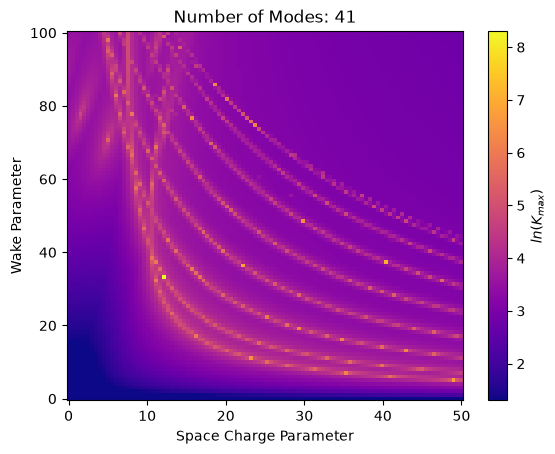

In [241]:
fig, ax = plt.subplots()

pcm = ax.pcolormesh(qrange, wrange, log_kmax, norm='linear', cmap='plasma')
ax.set_yscale('linear')
ax.set_xlabel('Space Charge Parameter')
ax.set_ylabel('Wake Parameter')
plt.title(f"Number of Modes: {2*n_max+1}")
plt.colorbar(pcm, ax=ax, label = rf"$ln(K_{{max}})$")
plt.savefig(f"../../plots/kmax_paramscan_theta_{n_modes}modes")
plt.show()

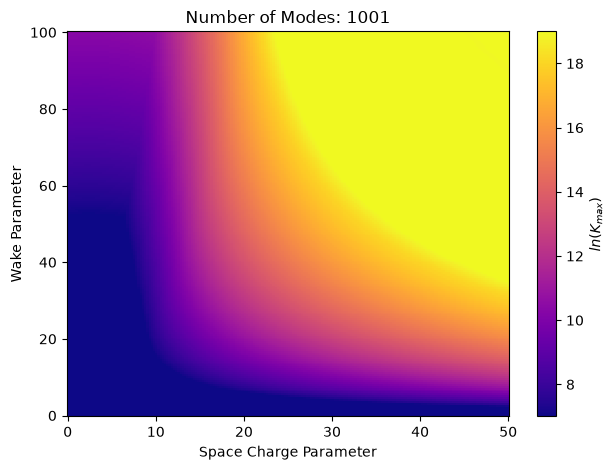

In [75]:
df = pd.read_csv('../../data/1001modes_50qmax_100wmax_200reso_logkmax.csv')

# --- Matrix reconstruction ---
imeigdf = df[df.source == 'matrix']
imeig_data = imeigdf.pivot(index='row', columns='col', values='value').to_numpy()

# --- Array reconstruction ---
qrange_data = df[df.source == 'q'].sort_values('row')['value'].to_numpy()
wrange_data = df[df.source == 'w'].sort_values('row')['value'].to_numpy()

cmap = plt.cm.plasma.copy()

fig, ax = plt.subplots()
#mcolors.Normalize(vmin=1, vmax=12)
pcm = ax.pcolormesh(qrange_data, wrange_data, imeig_data, norm=mcolors.Normalize(vmin=7, vmax=19), cmap=cmap)
#ax.set_yscale('log')
ax.set_xlabel('Space Charge Parameter')
ax.set_ylabel('Wake Parameter')
plt.title("Number of Modes: 1001")
plt.colorbar(pcm, ax=ax, label = rf"$ln(K_{{max}})$")
plt.tight_layout()
plt.savefig(f"../../plots/kmax_paramscan_theta_1001modes_bar.png", dpi=900)
plt.show()